# Distribution plots

## Learning objectives

By the end of this notebook you will be able to:

- draw histograms and density curves with histplot and kdeplot
- compare distributions between groups
- use ECDF plots and rug plots
- describe a distribution's shape: centre, spread, skew and modes

## Introduction

Looking at a variable's distribution is the first step with any numeric data. It shows the typical
value, how much values vary, whether the distribution is symmetric or skewed, and whether there are
several groups hidden inside one variable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
RAW = "../datasets/raw/"

In [2]:
sns.set_theme(style="whitegrid")
penguins = sns.load_dataset("penguins")
tips = sns.load_dataset("tips")
labs = pd.read_csv(RAW + "lab_results.csv")

## histplot

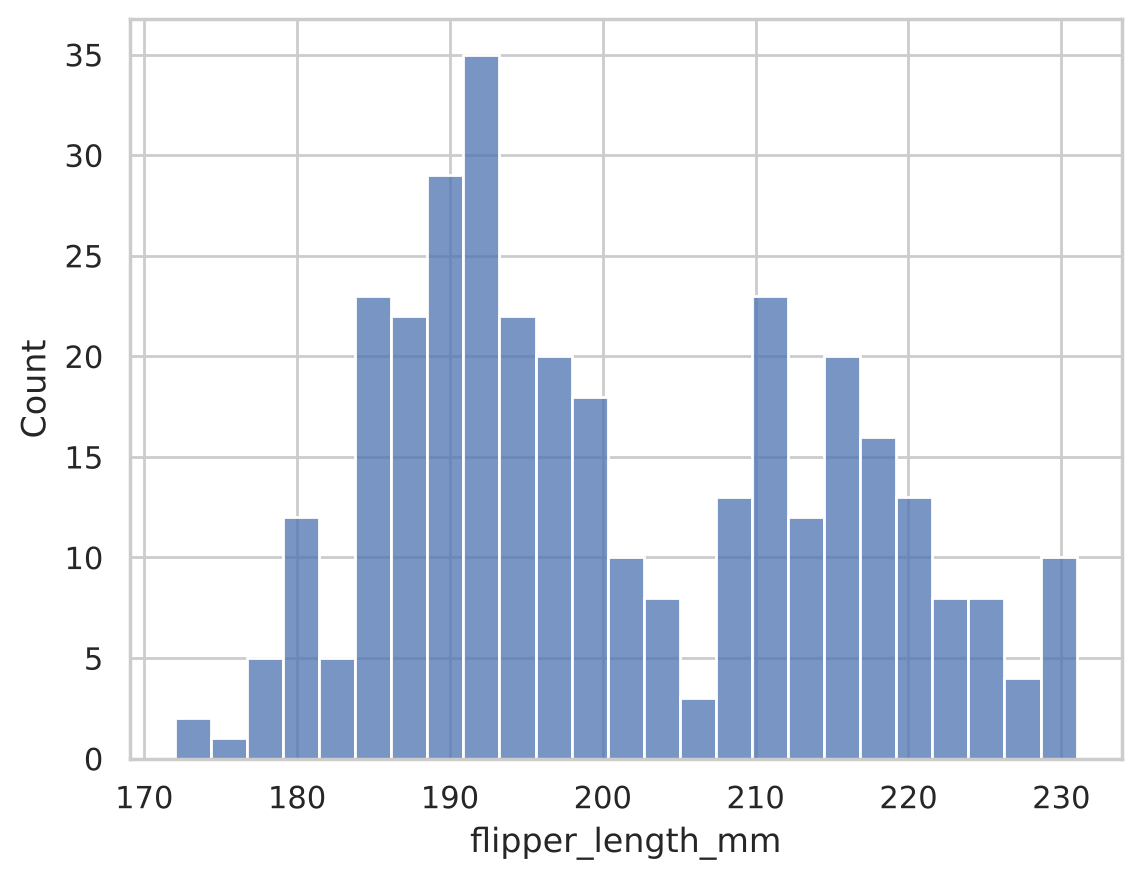

In [3]:
sns.histplot(data=penguins, x="flipper_length_mm", bins=25)
plt.show()

**Reading it:** the distribution has two humps (it is *bimodal*). Two humps usually mean two groups
mixed together. Colouring by species shows which:

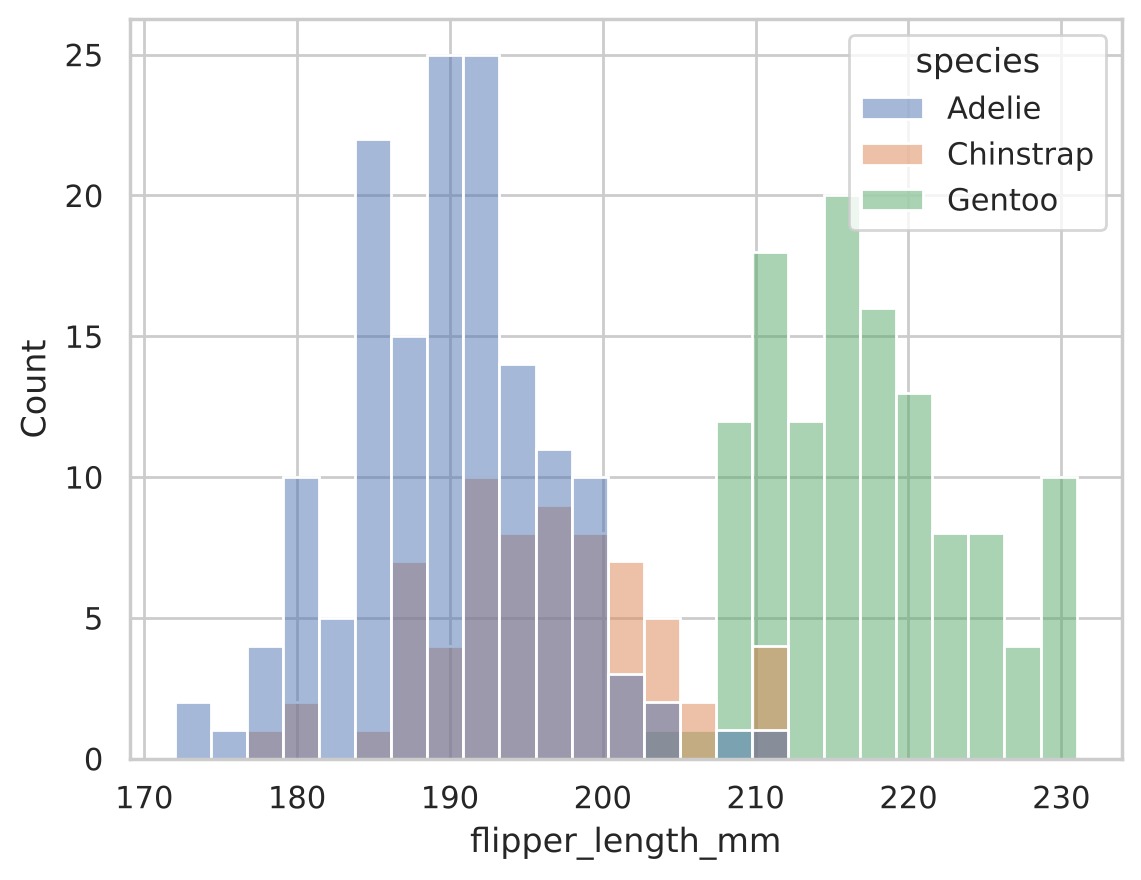

In [4]:
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", bins=25, multiple="layer", alpha=0.5)
plt.show()

Gentoo penguins form the upper hump; Adelie and Chinstrap overlap in the lower one. `multiple=` can be
`"layer"` (overlapping), `"stack"`, `"dodge"` (side by side) or `"fill"` (proportions).

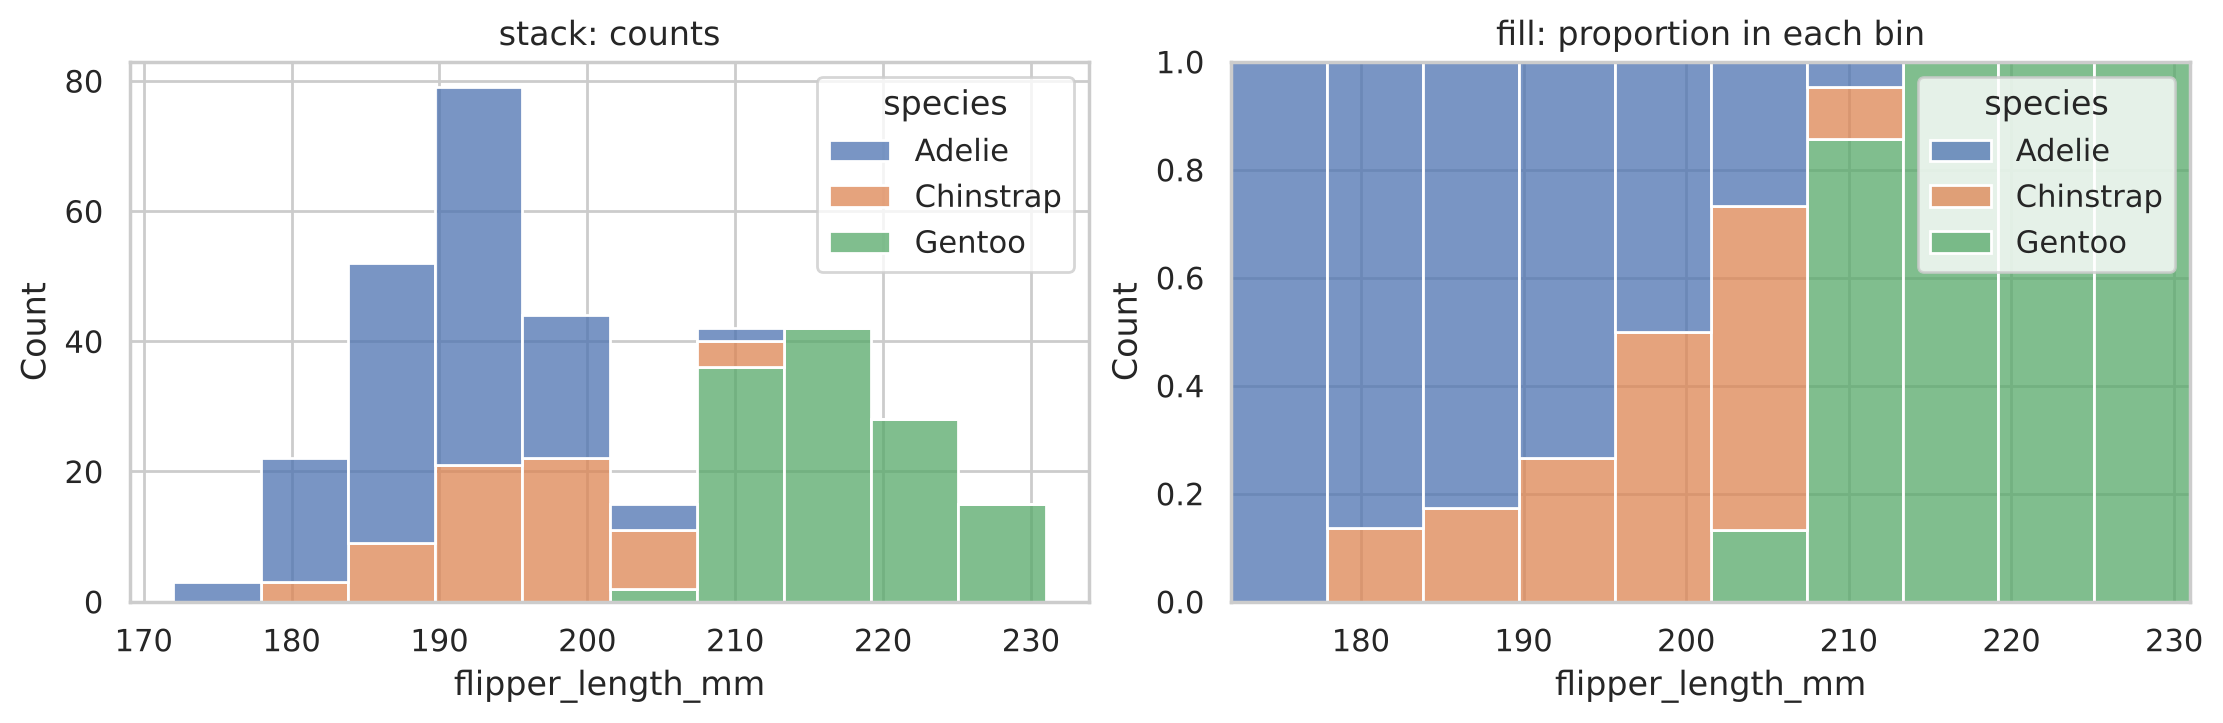

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", multiple="stack", ax=axes[0])
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", multiple="fill", ax=axes[1])
axes[0].set_title("stack: counts")
axes[1].set_title("fill: proportion in each bin")
plt.show()

## Skewness

A long right tail means a few large values pull the mean above the median.

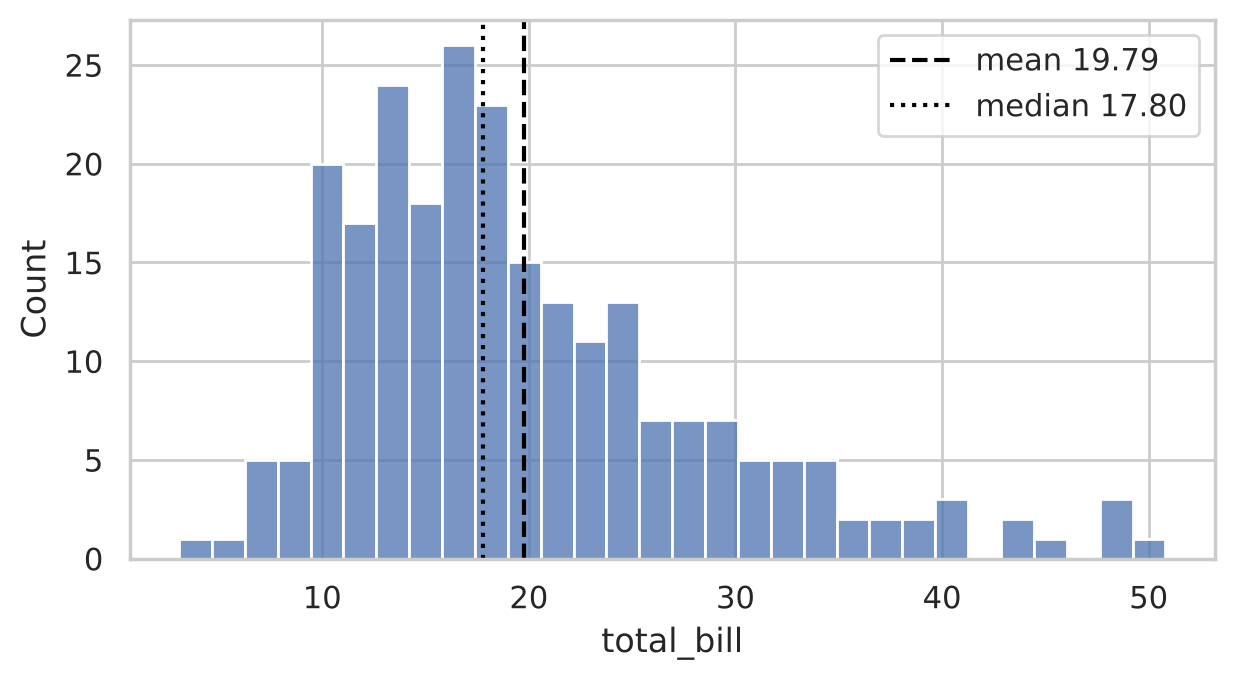

skewness: 1.13


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=tips, x="total_bill", bins=30, ax=ax)
ax.axvline(tips["total_bill"].mean(), color="black", linestyle="--", label=f"mean {tips['total_bill'].mean():.2f}")
ax.axvline(tips["total_bill"].median(), color="black", linestyle=":", label=f"median {tips['total_bill'].median():.2f}")
ax.legend()
plt.show()
print("skewness:", round(tips["total_bill"].skew(), 2))

Positive skewness confirms the right skew. For skewed variables, report the median and interquartile
range rather than only the mean and standard deviation.

## kdeplot: smooth density

A kernel density estimate (KDE) draws a smooth curve instead of bars. The area under the curve is 1.
It is good for comparing overlapping groups, but it can suggest values where there are none (below zero,
for example), so check it against a histogram.

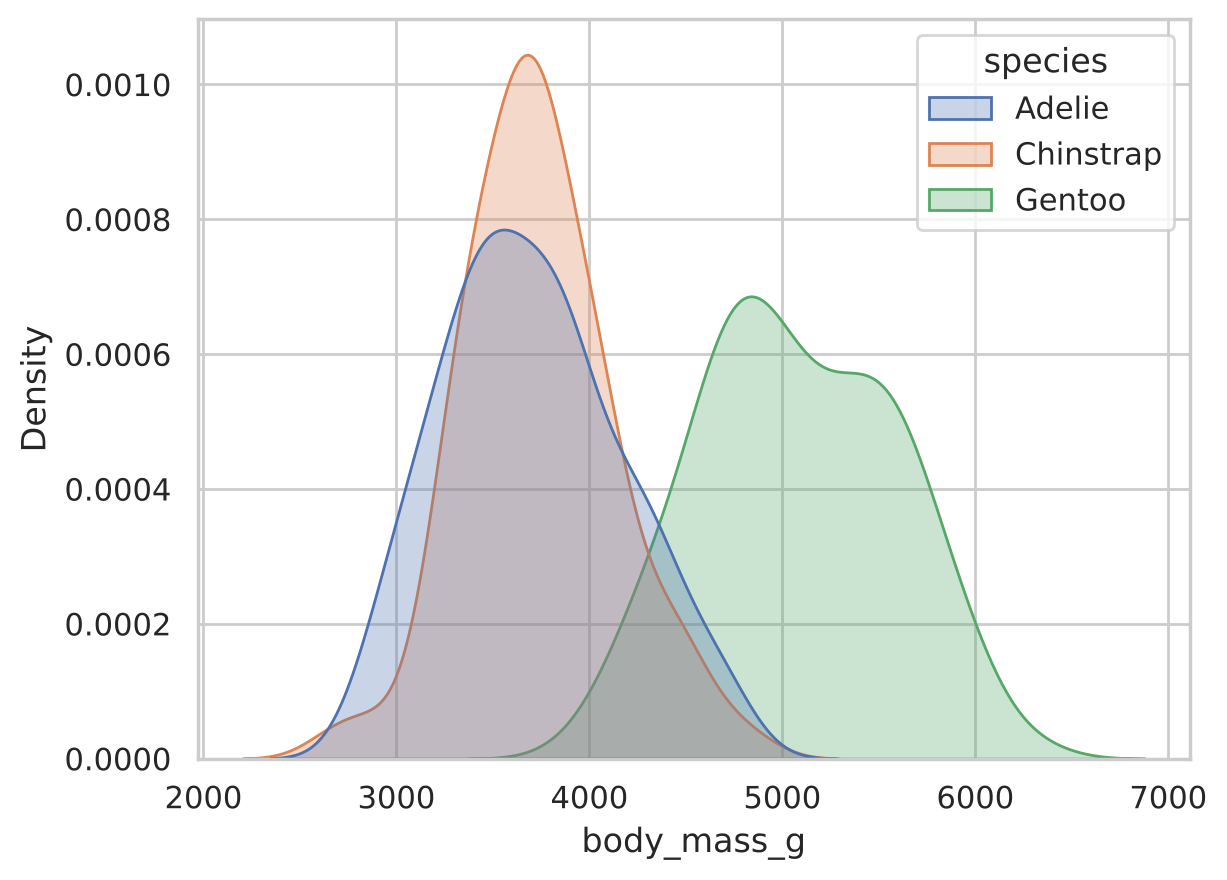

In [7]:
sns.kdeplot(data=penguins, x="body_mass_g", hue="species", fill=True, alpha=0.3, common_norm=False)
plt.show()

`common_norm=False` scales each group's curve to area 1 separately, so a small group is not drawn
smaller just because it has fewer members.

`bw_adjust` controls smoothness, like the bin count of a histogram:

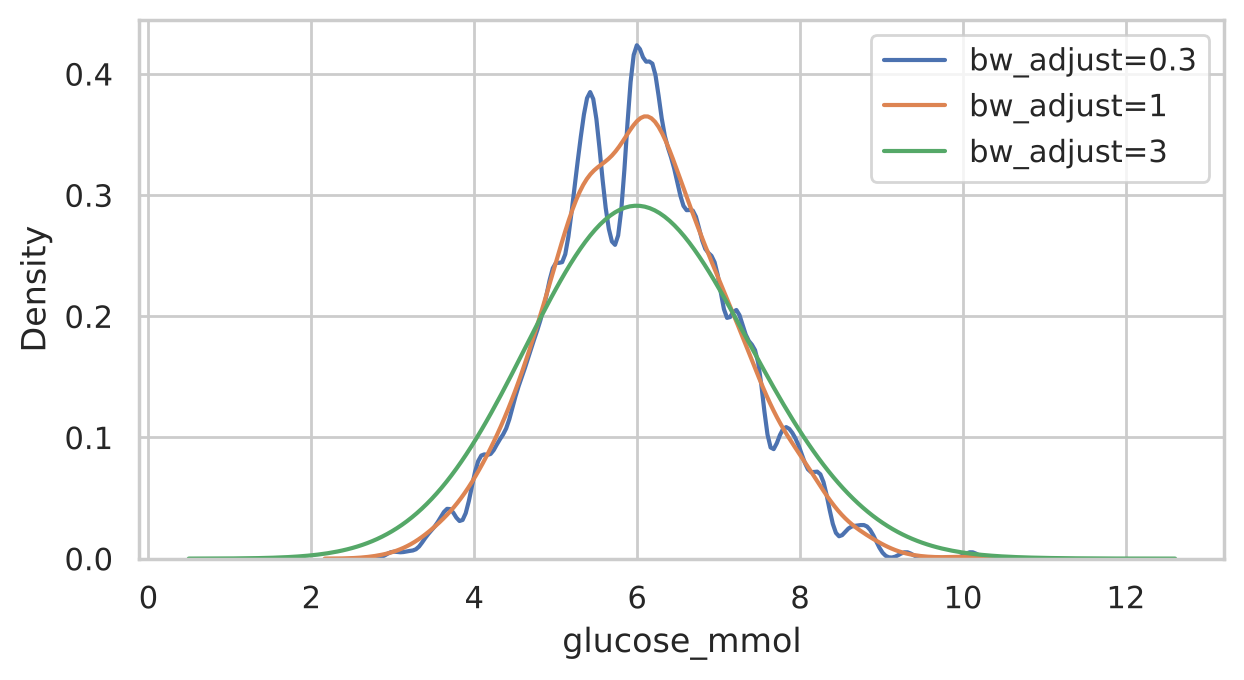

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for bw in [0.3, 1, 3]:
    sns.kdeplot(data=labs, x="glucose_mmol", bw_adjust=bw, label=f"bw_adjust={bw}", ax=ax)
ax.legend()
plt.show()

## Histogram with a density curve

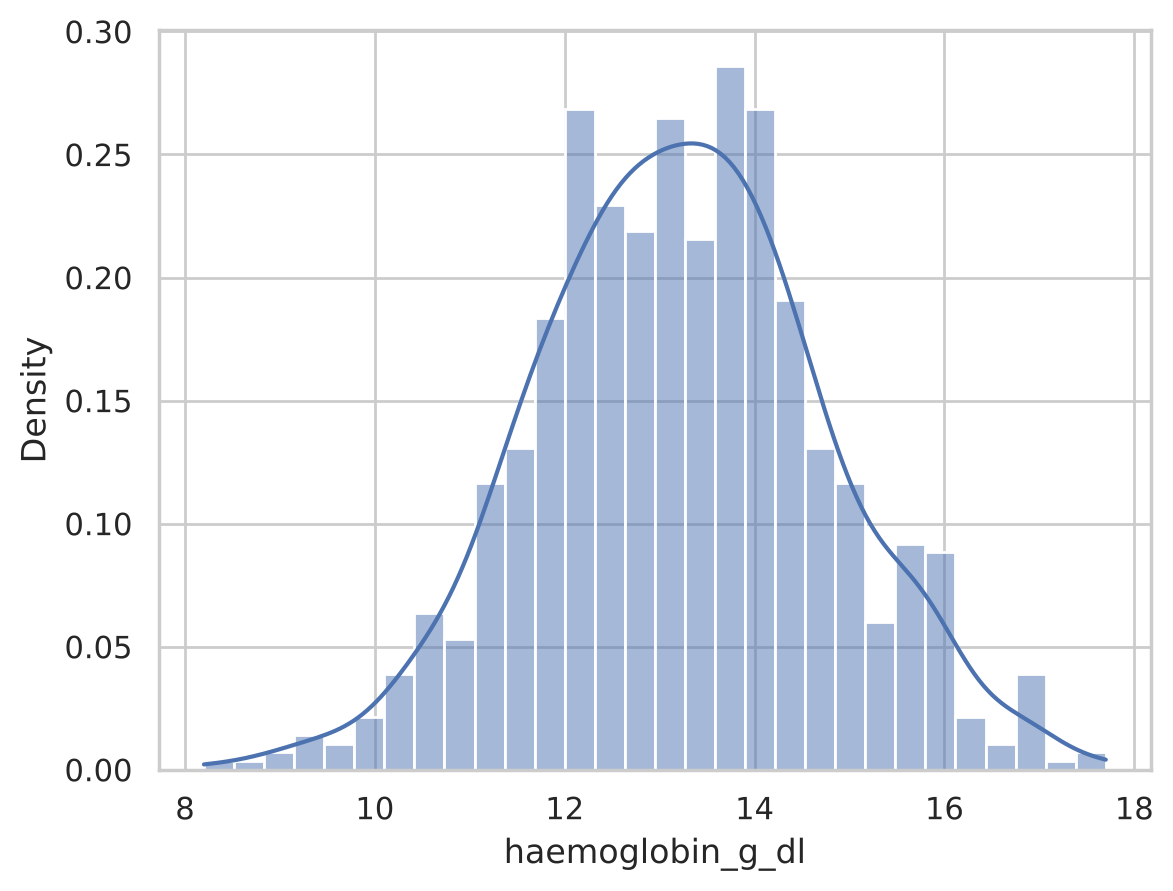

In [9]:
sns.histplot(data=labs, x="haemoglobin_g_dl", kde=True, stat="density", bins=30)
plt.show()

## displot: panels

The figure-level `displot` draws one panel per group with `col` or `row`:

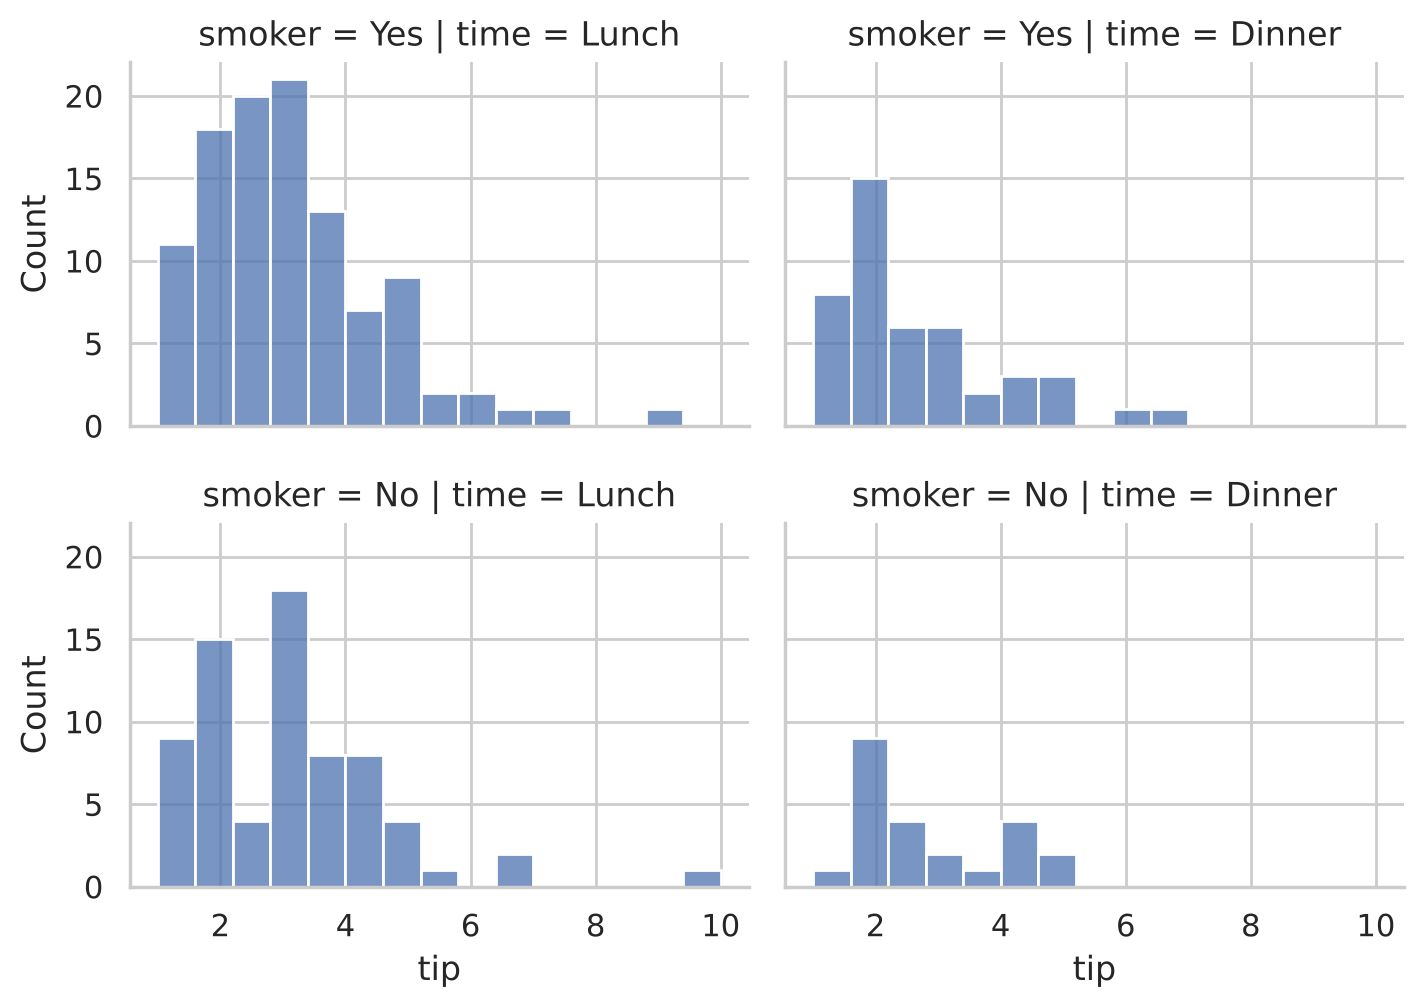

In [10]:
sns.displot(data=tips, x="tip", col="time", row="smoker", bins=15, height=2.6, aspect=1.4)
plt.show()

## ECDF

An *empirical cumulative distribution function* shows, for each value, the proportion of observations
at or below it. It needs no bins, and medians and percentiles can be read straight off the y-axis.

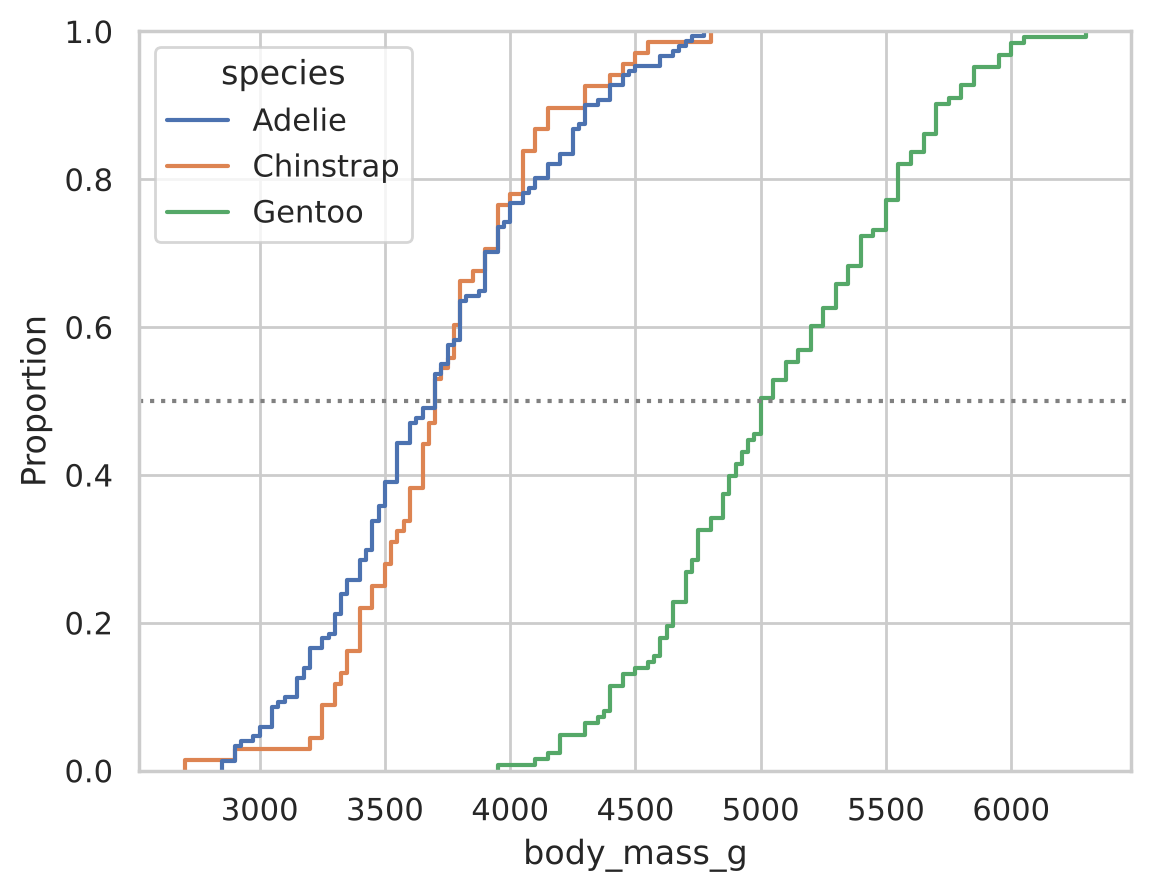

In [11]:
ax = sns.ecdfplot(data=penguins, x="body_mass_g", hue="species")
ax.axhline(0.5, color="grey", linestyle=":")
plt.show()

Where each curve crosses 0.5 is that species' median. A curve further to the right means heavier
penguins throughout the distribution.

## Rug plot

Tick marks for each observation, useful with small samples:

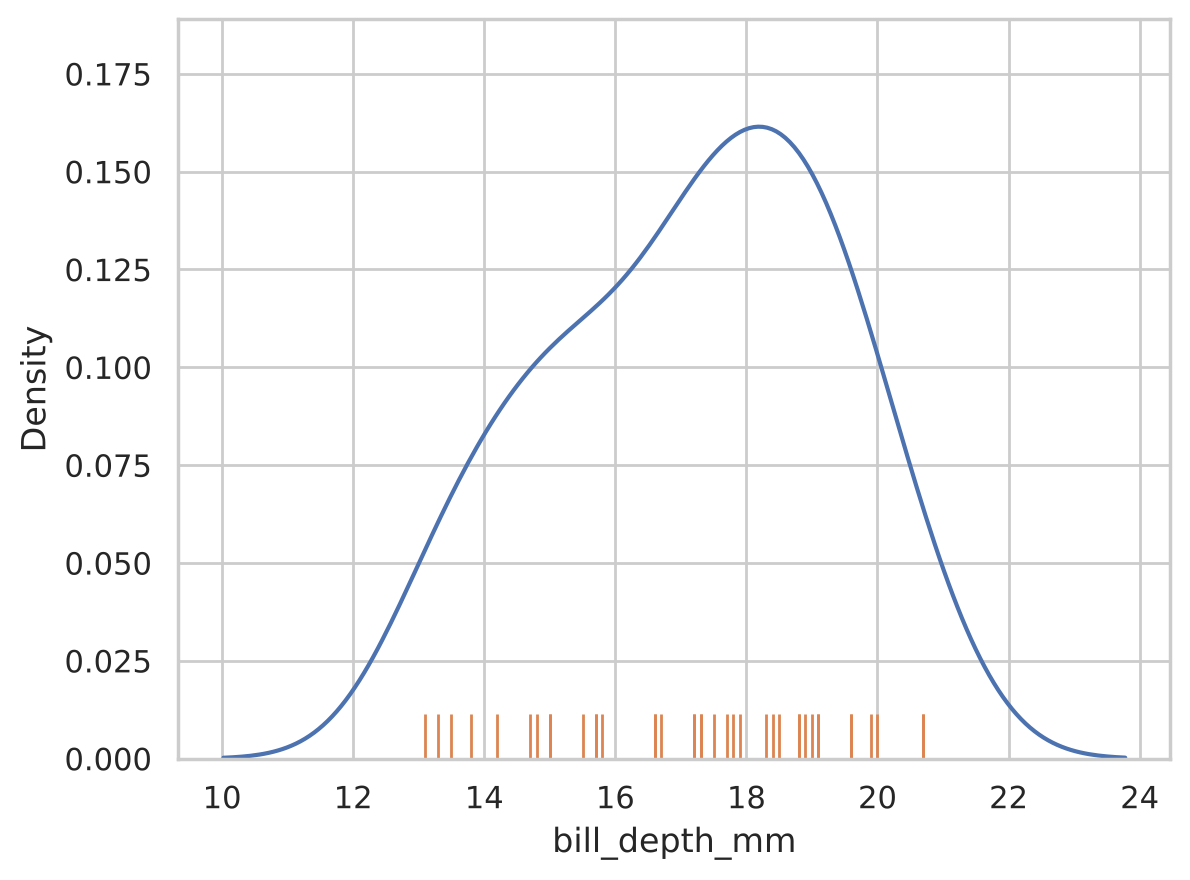

In [12]:
small = penguins.sample(40, random_state=2)
sns.kdeplot(data=small, x="bill_depth_mm")
sns.rugplot(data=small, x="bill_depth_mm", height=0.06)
plt.show()

## Two variables: bivariate distributions

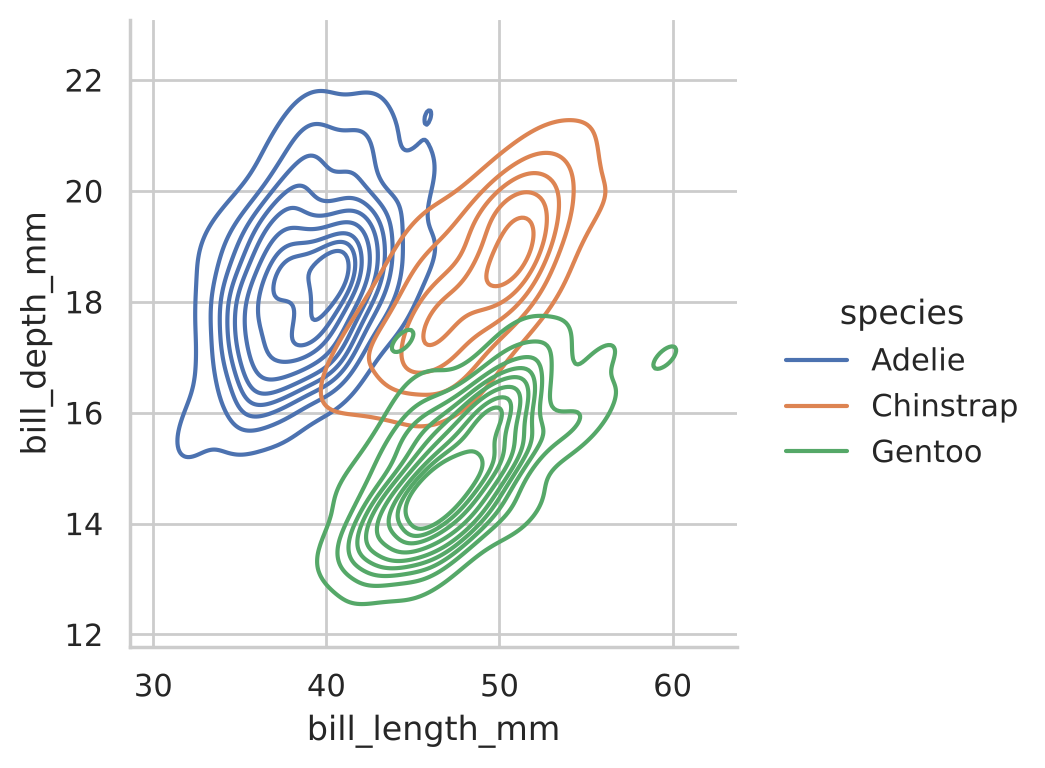

In [13]:
sns.displot(data=penguins, x="bill_length_mm", y="bill_depth_mm", kind="kde", hue="species", height=4)
plt.show()

The contours are like a map's height lines: each species occupies its own region of bill length and
depth, which is why these two measurements separate the species well.

## Practise

Exercises for this folder are in `exercises/Seaborn_Exercises.ipynb`.

## Further reading

- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html)
- [Visualising distributions](https://seaborn.pydata.org/tutorial/distributions.html)
- [histplot reference](https://seaborn.pydata.org/generated/seaborn.histplot.html)